##### loading the dataset and required libraries


In [1]:
import matplotlib.pyplot  as plt
import seaborn as sns

In [2]:
import pandas as pd
data=pd.read_csv(r'C:\Users\Deekshit Gangadhar\Downloads\archive (3)\Loan_default.csv')
data

,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
255342,8C6S86ESGC,19,37979,210682,541,109,4,14.11,12,0.85,Bachelor's,Full-time,Married,No,No,Other,No,0
255343,98R4KDHNND,32,51953,189899,511,14,2,11.55,24,0.21,High School,Part-time,Divorced,No,No,Home,No,1
255344,XQK1UUUNGP,56,84820,208294,597,70,3,5.29,60,0.50,High School,Self-employed,Married,Yes,Yes,Auto,Yes,0
255345,JAO28CPL4H,42,85109,60575,809,40,1,20.90,48,0.44,High School,Part-time,Single,Yes,Yes,Other,No,0


##### data cleaning

In [3]:

data.isnull().sum()  ### checking for missing values

LoanID            0
Age               0
Income            0
LoanAmount        0
CreditScore       0
MonthsEmployed    0
NumCreditLines    0
InterestRate      0
LoanTerm          0
DTIRatio          0
Education         0
EmploymentType    0
MaritalStatus     0
HasMortgage       0
HasDependents     0
LoanPurpose       0
HasCoSigner       0
Default           0
dtype: int64

In [4]:
print(data.duplicated().sum())  ## checking for duplicate rows

0


In [5]:
data1=data.drop(['LoanID'],axis=1)   ## 'LoanID' column is not needed so we drop it
data1

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
255342,19,37979,210682,541,109,4,14.11,12,0.85,Bachelor's,Full-time,Married,No,No,Other,No,0
255343,32,51953,189899,511,14,2,11.55,24,0.21,High School,Part-time,Divorced,No,No,Home,No,1
255344,56,84820,208294,597,70,3,5.29,60,0.50,High School,Self-employed,Married,Yes,Yes,Auto,Yes,0
255345,42,85109,60575,809,40,1,20.90,48,0.44,High School,Part-time,Single,Yes,Yes,Other,No,0


##### Exploitary Data Analysis

In [6]:
data1.shape   ### number of rows and columns

(255347, 17)

In [7]:
data1.info()

<class 'pandas.DataFrame'>
RangeIndex: 255347 entries, 0 to 255346
Data columns (total 17 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   Age             255347 non-null  int64  
 1   Income          255347 non-null  int64  
 2   LoanAmount      255347 non-null  int64  
 3   CreditScore     255347 non-null  int64  
 4   MonthsEmployed  255347 non-null  int64  
 5   NumCreditLines  255347 non-null  int64  
 6   InterestRate    255347 non-null  float64
 7   LoanTerm        255347 non-null  int64  
 8   DTIRatio        255347 non-null  float64
 9   Education       255347 non-null  str    
 10  EmploymentType  255347 non-null  str    
 11  MaritalStatus   255347 non-null  str    
 12  HasMortgage     255347 non-null  str    
 13  HasDependents   255347 non-null  str    
 14  LoanPurpose     255347 non-null  str    
 15  HasCoSigner     255347 non-null  str    
 16  Default         255347 non-null  int64  
dtypes: float64(2), int64(

In [8]:
data1.describe()

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Default
count,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000
mean,43.498306,82499.304597,127578.865512,574.264346,59.541976,2.501036,13.492773,36.025894,0.500212,0.116128
std,14.990258,38963.013729,70840.706142,158.903867,34.643376,1.117018,6.636443,16.969330,0.230917,0.320379
min,18.000000,15000.000000,5000.000000,300.000000,0.000000,1.000000,2.000000,12.000000,0.100000,0.000000
25%,31.000000,48825.500000,66156.000000,437.000000,30.000000,2.000000,7.770000,24.000000,0.300000,0.000000
50%,43.000000,82466.000000,127556.000000,574.000000,60.000000,2.000000,13.460000,36.000000,0.500000,0.000000
75%,56.000000,116219.000000,188985.000000,712.000000,90.000000,3.000000,19.250000,48.000000,0.700000,0.000000
max,69.000000,149999.000000,249999.000000,849.000000,119.000000,4.000000,25.000000,60.000000,0.900000,1.000000


In [9]:
data1.value_counts()

Age  Income  LoanAmount  CreditScore  MonthsEmployed  NumCreditLines  InterestRate  LoanTerm  DTIRatio  Education    EmploymentType  MaritalStatus  HasMortgage  HasDependents  LoanPurpose  HasCoSigner  Default
56   85994   50587       520          80              4               15.23         36        0.44      Bachelor's   Full-time       Divorced       Yes          Yes            Other        Yes          0          1
69   50432   124440      458          15              1               4.81          60        0.68      Master's     Full-time       Married        No           No             Other        Yes          0          1
46   84208   129188      451          26              3               21.17         24        0.31      Master's     Unemployed      Divorced       Yes          Yes            Auto         No           1          1
32   31713   44799       743          0               3               7.07          24        0.23      High School  Full-time       Married     

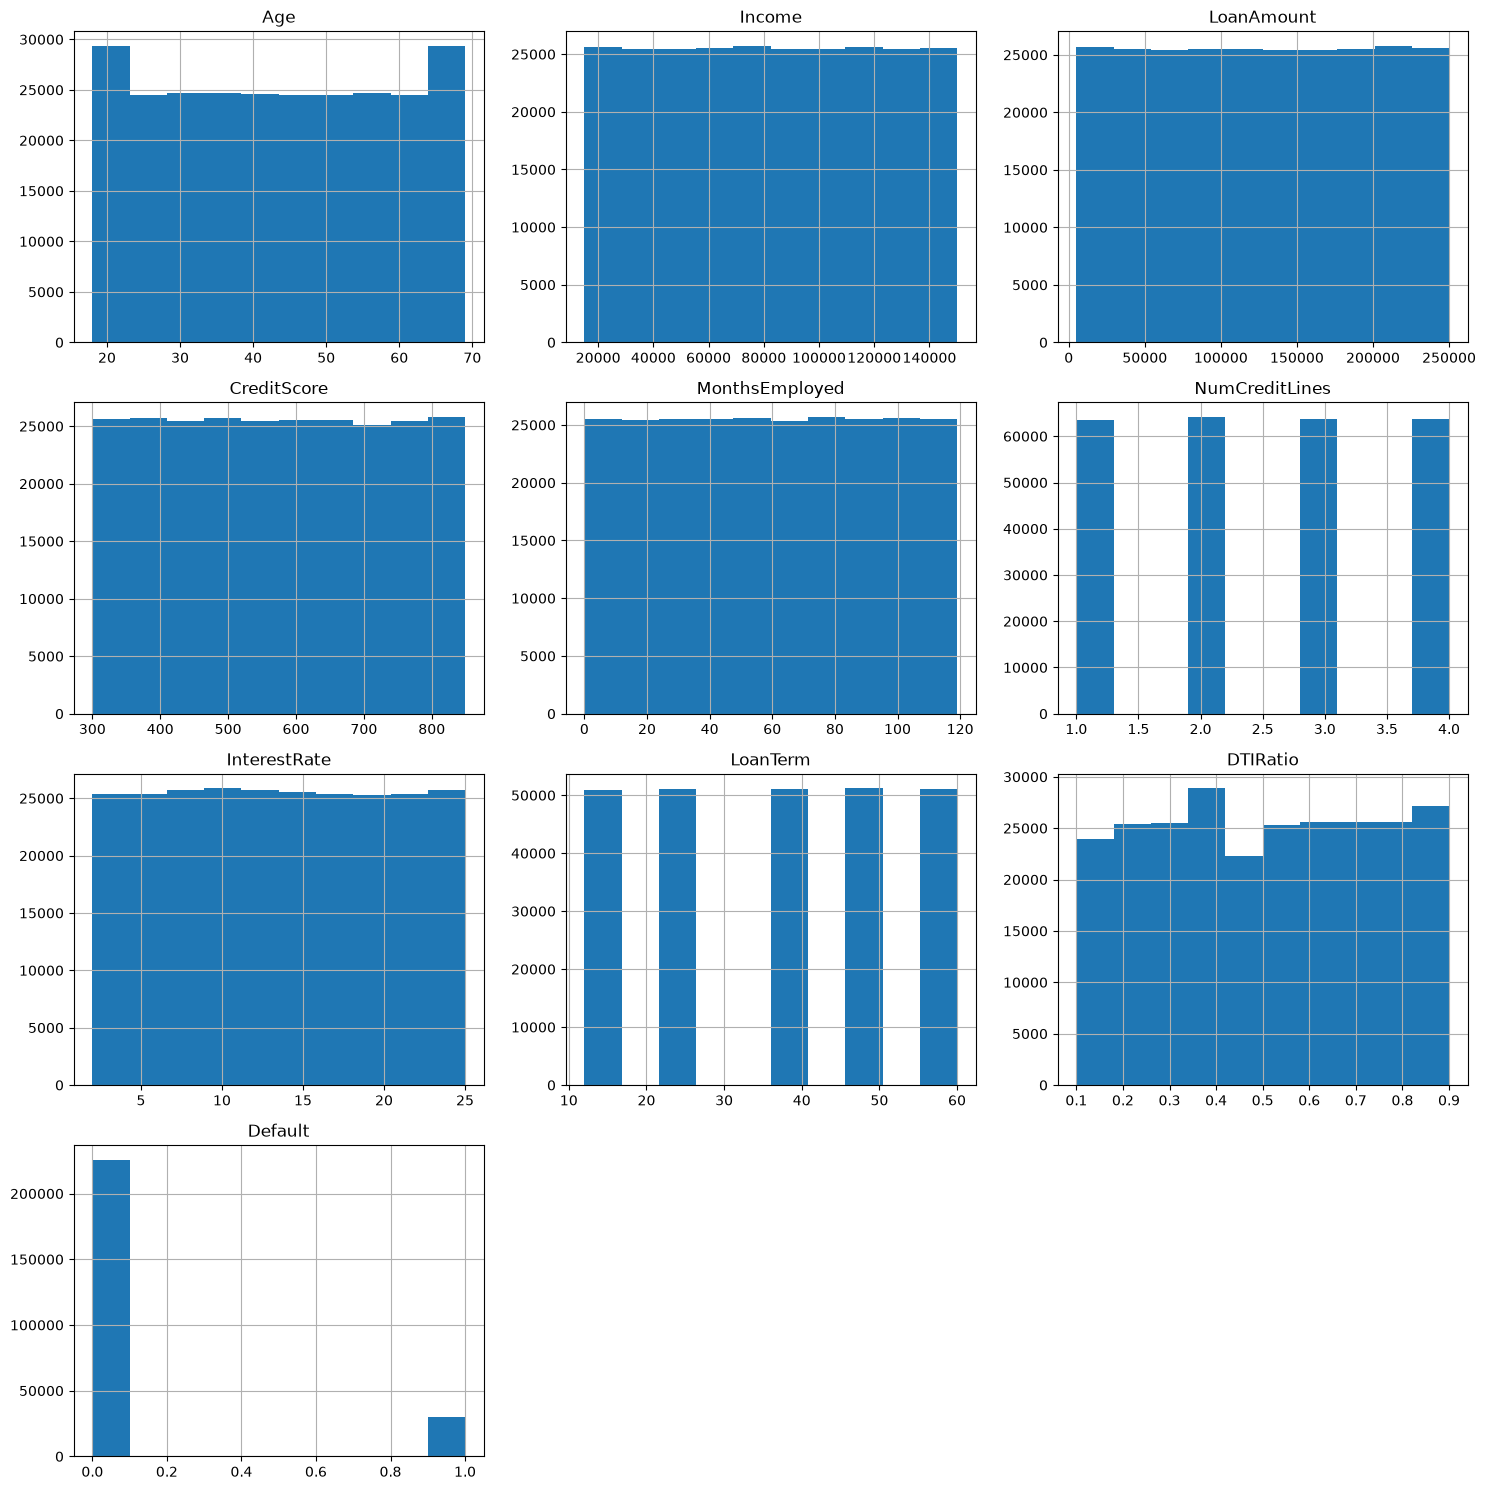

In [10]:
data.hist(figsize=(15,15),bins=10)   ### histogram of columns
plt.tight_layout()
plt.show()

##### Outlier Analysis

In [11]:
num_cols=data1.select_dtypes(include='number').columns  ### identifying numerical columns
num_cols



Index(['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed',
       'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio', 'Default'],
      dtype='str')

In [12]:
num_cols=num_cols.drop(['Default'],errors="ignore")  ## removing target sample from outlier analysis
num_cols

Index(['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed',
       'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio'],
      dtype='str')

In [13]:
len(num_cols)

9

In [14]:
data2=data1[num_cols]
data2

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio
0,56,85994,50587,520,80,4,15.23,36,0.44
1,69,50432,124440,458,15,1,4.81,60,0.68
2,46,84208,129188,451,26,3,21.17,24,0.31
3,32,31713,44799,743,0,3,7.07,24,0.23
4,60,20437,9139,633,8,4,6.51,48,0.73
...,...,...,...,...,...,...,...,...,...
255342,19,37979,210682,541,109,4,14.11,12,0.85
255343,32,51953,189899,511,14,2,11.55,24,0.21
255344,56,84820,208294,597,70,3,5.29,60,0.50
255345,42,85109,60575,809,40,1,20.90,48,0.44


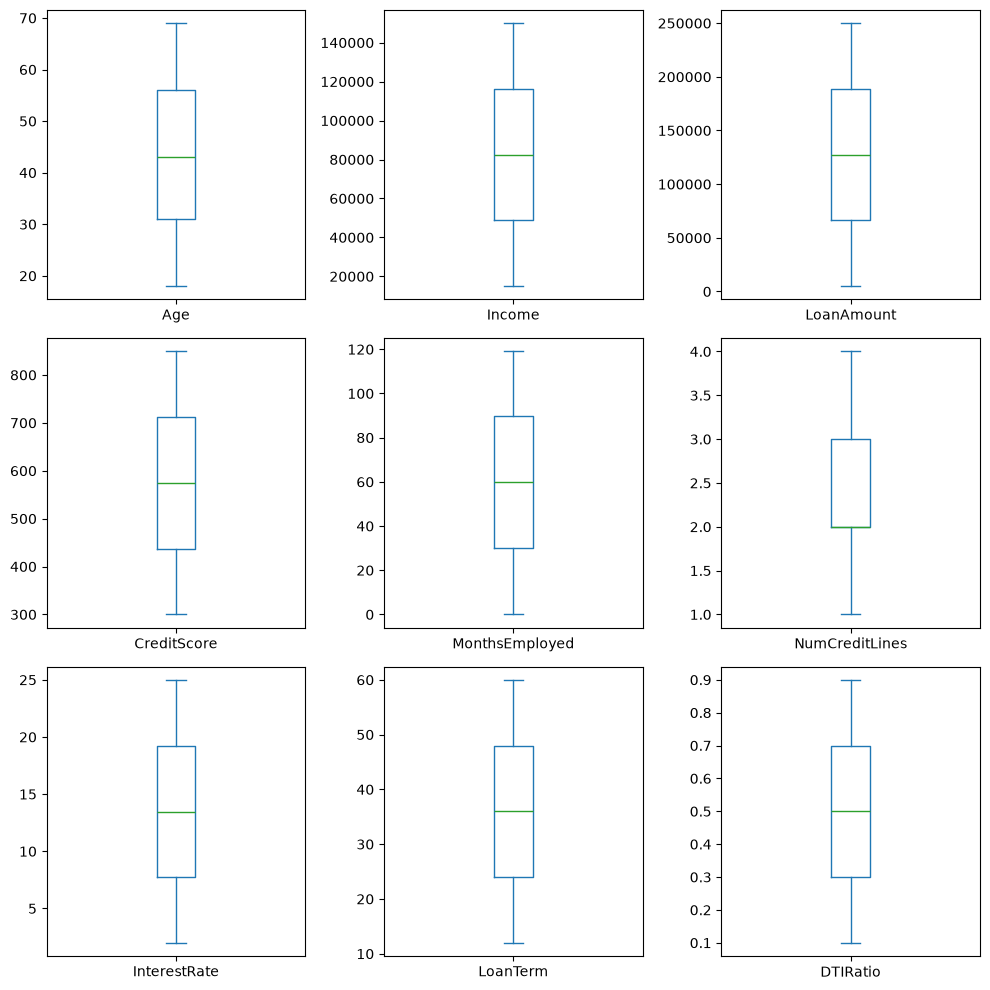

In [15]:
data2.plot(kind='box',subplots=True,layout=(3,3),figsize=(10,10))  ###boxplot
plt.tight_layout()

##### Categorical Data Analysis

In [16]:
data1.dtypes

Age                 int64
Income              int64
LoanAmount          int64
CreditScore         int64
MonthsEmployed      int64
NumCreditLines      int64
InterestRate      float64
LoanTerm            int64
DTIRatio          float64
Education             str
EmploymentType        str
MaritalStatus         str
HasMortgage           str
HasDependents         str
LoanPurpose           str
HasCoSigner           str
Default             int64
dtype: object

In [17]:
cat_cols=data1.select_dtypes(include="str").columns    #### extracting string columns
cat_cols

Index(['Education', 'EmploymentType', 'MaritalStatus', 'HasMortgage',
       'HasDependents', 'LoanPurpose', 'HasCoSigner'],
      dtype='str')

In [18]:
data1.select_dtypes(include="str")   ### 1 ordinal categories and 6 nominal categories

,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner
0,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes
1,Master's,Full-time,Married,No,No,Other,Yes
2,Master's,Unemployed,Divorced,Yes,Yes,Auto,No
3,High School,Full-time,Married,No,No,Business,No
4,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No
...,...,...,...,...,...,...,...
255342,Bachelor's,Full-time,Married,No,No,Other,No
255343,High School,Part-time,Divorced,No,No,Home,No
255344,High School,Self-employed,Married,Yes,Yes,Auto,Yes
255345,High School,Part-time,Single,Yes,Yes,Other,No


In [19]:
for col in cat_cols:     ### inspecting unique values
    print(f"\n{col}:")
    print(data1[col].unique())


Education:
<StringArray>
['Bachelor's', 'Master's', 'High School', 'PhD']
Length: 4, dtype: str

EmploymentType:
<StringArray>
['Full-time', 'Unemployed', 'Self-employed', 'Part-time']
Length: 4, dtype: str

MaritalStatus:
<StringArray>
['Divorced', 'Married', 'Single']
Length: 3, dtype: str

HasMortgage:
<StringArray>
['Yes', 'No']
Length: 2, dtype: str

HasDependents:
<StringArray>
['Yes', 'No']
Length: 2, dtype: str

LoanPurpose:
<StringArray>
['Other', 'Auto', 'Business', 'Home', 'Education']
Length: 5, dtype: str

HasCoSigner:
<StringArray>
['Yes', 'No']
Length: 2, dtype: str


##### Data Splitting

In [20]:
from sklearn.model_selection import train_test_split
y=data1['Default']
x=data1.drop(columns=['Default'])
x_train,x_test,y_train,y_test=train_test_split(x,y,train_size=0.8,random_state=42,stratify=y)

##### Categorical Encoding

In [21]:
### label encoding for Education
from sklearn.preprocessing import LabelEncoder

lab = LabelEncoder()
x_train['Education'] = lab.fit_transform(x_train['Education'])
x_test['Education'] = lab.transform(x_test['Education'])

In [23]:

# One Hot Encoding
from sklearn.preprocessing import OneHotEncoder

a = ['EmploymentType', 'MaritalStatus', 'HasMortgage',
     'HasDependents', 'LoanPurpose', 'HasCoSigner']

one = OneHotEncoder(sparse_output=False, dtype=int)

encoded = one.fit_transform(x_train[a])
encoded_test = one.transform(x_test[a])

encoded_cols = one.get_feature_names_out(a)

x_train[encoded_cols] = encoded
x_test[encoded_cols] = encoded_test

x_train = x_train.drop(columns=a)
x_test = x_test.drop(columns=a)

In [24]:
### dropping one reference category from each one-hot encoded feature
drop_cols = [
    'EmploymentType_Unemployed',
    'MaritalStatus_Single',
    'HasMortgage_No',
    'HasDependents_No',
    'LoanPurpose_Other',
    'HasCoSigner_No'
]

x_train = x_train.drop(columns=drop_cols)
x_test = x_test.drop(columns=drop_cols)

In [25]:
x_train

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,...,EmploymentType_Self-employed,MaritalStatus_Divorced,MaritalStatus_Married,HasMortgage_Yes,HasDependents_Yes,LoanPurpose_Auto,LoanPurpose_Business,LoanPurpose_Education,LoanPurpose_Home,HasCoSigner_Yes
15826,45,37039,247916,624,19,2,4.62,60,0.85,1,...,0,0,1,0,1,1,0,0,0,0
147371,48,133963,66275,494,119,3,14.72,48,0.49,3,...,1,0,1,1,1,0,0,0,0,1
178180,47,100204,6967,718,108,3,5.51,24,0.76,1,...,1,0,0,1,1,0,1,0,0,1
126915,42,36078,25966,344,2,3,18.29,36,0.76,0,...,1,0,1,0,1,0,0,1,0,0
163930,20,99464,248557,318,74,3,19.45,60,0.45,0,...,0,1,0,0,0,1,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59108,18,115282,142016,601,50,3,3.43,36,0.36,2,...,0,1,0,0,0,0,1,0,0,1
71610,67,39547,94145,383,82,4,3.32,48,0.80,3,...,0,0,1,0,0,1,0,0,0,1
85645,60,48470,29331,590,42,1,12.67,12,0.83,1,...,1,0,0,0,0,1,0,0,0,0
21010,37,56697,76419,461,15,2,19.61,60,0.24,1,...,0,1,0,1,1,0,0,0,0,0


In [26]:
x_test

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,...,EmploymentType_Self-employed,MaritalStatus_Divorced,MaritalStatus_Married,HasMortgage_Yes,HasDependents_Yes,LoanPurpose_Auto,LoanPurpose_Business,LoanPurpose_Education,LoanPurpose_Home,HasCoSigner_Yes
211648,54,20956,87156,789,102,4,8.99,24,0.65,2,...,0,0,0,1,1,0,0,1,0,0
201101,49,138499,227279,603,102,4,2.46,12,0.67,1,...,0,0,1,1,0,0,0,0,1,0
140423,69,22538,48532,337,48,2,16.15,24,0.74,1,...,1,1,0,1,1,0,0,0,0,0
204530,58,34754,134218,531,107,3,24.73,60,0.55,2,...,0,0,1,0,0,0,0,1,0,0
166481,35,47430,130554,484,30,2,2.19,48,0.80,3,...,0,0,1,0,0,0,0,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
121374,27,63878,37277,525,86,2,19.27,48,0.22,1,...,1,0,1,1,0,0,0,0,1,1
131794,63,41977,27305,686,97,4,20.33,60,0.31,2,...,0,0,0,1,0,0,0,0,0,0
227111,38,39326,176514,523,94,2,10.68,36,0.54,3,...,0,0,1,0,1,1,0,0,0,1
58432,62,82045,159322,550,56,2,22.40,60,0.44,0,...,0,0,1,0,1,0,0,1,0,1


In [27]:
y_train

15826     0
147371    0
178180    0
126915    0
163930    1
         ..
59108     0
71610     0
85645     0
21010     0
7493      0
Name: Default, Length: 204277, dtype: int64

In [28]:
data1['Default'].value_counts()  ### there is severe class imbalance
data1['Default'].value_counts(normalize=True)*100

Default
0    88.387175
1    11.612825
Name: proportion, dtype: float64

##### Data Scaling

In [29]:
num_cols

Index(['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed',
       'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio'],
      dtype='str')

In [30]:
from sklearn.preprocessing import StandardScaler

ss = StandardScaler()
x_train[num_cols] = ss.fit_transform(x_train[num_cols])
x_test[num_cols] = ss.transform(x_test[num_cols])

##### Model Training


In [36]:
##### logistic Regression
from sklearn.linear_model import LogisticRegression
log=LogisticRegression(class_weight='balanced',random_state=42)
log.fit(x_train,y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the follo

In [41]:
### model evaluation
y_pred1=log.predict(x_test)
y_pred1

array([0, 0, 0, ..., 0, 0, 0], shape=(51070,))

In [38]:
y_test

211648    0
201101    0
140423    0
204530    0
166481    0
         ..
121374    1
131794    0
227111    0
58432     0
95842     0
Name: Default, Length: 51070, dtype: int64

In [39]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report)
print("confusion matrix :\n", confusion_matrix(y_test,y_pred1))
print("accuracy\n",accuracy_score(y_test,y_pred1))
print("precision\n",precision_score(y_test,y_pred1))
print("recall\n",recall_score(y_test,y_pred1))
print("f1 score\n",f1_score(y_test,y_pred1))

confusion matrix :
 [[30345 14794]
 [ 1756  4175]]
accuracy
 0.6759349911885647
precision
 0.22009594601718593
recall
 0.7039285112122745
f1 score
 0.3353413654618474
